In [1]:
import numpy as np  
import matplotlib.pyplot as plt

In [ ]:
def CrearEspacio(x1 = -20, x2 = 20, y1 = -20 ,y2 =20, Resolucion = 1000, n = 1):
    ''' 
    Tomas los limites superiores e inferiores de 'x' y 'y' y crea una grilla solo para el espacio 
    y crea otra con la misma forma de X llena del indice de refraccion deseado,
    que por defecto es n = 1
    '''    
    Espacio =np.array([np.linspace(x1, x2,Resolucion),np.linspace(y1, y2, Resolucion)])
    X , Y = np.meshgrid(Espacio[0], Espacio[1])
    EspacioIndices = np.full_like(X, fill_value = n, dtype=float)
    return Espacio, EspacioIndices, X, Y 


def DiaelectricoCircular(n=1, Origen =[0,0], Radio = 1):
    '''  
    Toma el indice de refraccion del circulo diaelectrico su centro y radio y modifica el espacio de indices con esos valores creando el circulo
    '''
    EspacioIndices[(X - Origen[0])**2 + (Y - Origen[1])**2 <= Radio**2] = n
'''
def DiaelectricoRectangular(n=1,IntervaloX=[Espacio[0, 0], Espacio[0, -1]],IntervaloY=[Espacio[1, 0], Espacio[1, -1]]):
    mask = ((X >= IntervaloX[0]) & (X <= IntervaloX[1]) & (Y >= IntervaloY[0]) & (Y <= IntervaloY[1]))
    EspacioIndices[mask] = n

#Es posible crear un diaelectrico rectangular pero el codigo no lo va a simular incorrectamente en estado actual, sera un trabajo para despues, solo me enfocare en circulos

def IndiceEspacio(x, y):
    #Toma las coordenadas dadas y devuelve el indice de refraccion del espacio de indices de esa posicion, quedo deprecado, no daba los mejores resultados.
    #Generaba problemas en los cambios de frontera 
    j = np.argmin(np.abs(Espacio[0] - x))   # columna (x)
    i = np.argmin(np.abs(Espacio[1] - y))   # fila (y)
    return EspacioIndices[i, j]

'''
def AnguloVec(Vec1,Vec2):
    #Toma dos vectores y calcula el angulo entre estos
    return np.arccos((np.vdot(Vec1,Vec2))/(np.linalg.norm(Vec1)*np.linalg.norm(Vec2) ))

def AnguloRefractado(n1,n2,Oi):
    #Realiza el calculo del angulo refractado a partir de la Ley de Snell
    return np.arcsin(n1/n2 * np.sin(Oi))

def VectorCirculo(a,b,OrigenC):
    #Devuelve el vector normal a la superficie del punto en el que incide el vector en el circulo
    return np.array([a - OrigenC[0], b - OrigenC[1]])

def Rotar(vec, ang):
    #Rota el vector dado utilizando la matriz de rotacion
    c, s = np.cos(ang), np.sin(ang)
    return np.array([c * vec[0] - s * vec[1], s * vec[0] + c * vec[1]])

def Refractar(VecI, VecN, n1, n2):
    #Toma el vector incidente sobre el circulo y el normal  para devolver el vector transmitido
    #El vector transmitido es equivalente a una rotacion del vector incidente dado el Angulo Refractado
    a = -VecN                                             
    Anguloincidente = AnguloVec(VecI, a)                 
    AnguloTransmitido = AnguloRefractado(n1, n2, Anguloincidente)

    signo = np.sign(a[0]*VecI[1] - a[1]*VecI[0])           # lado de la inclinación

    if np.isnan(AnguloTransmitido):                        # reflexión total
        return Rotar(VecN, -signo * Anguloincidente)
    return Rotar(VecI, -signo * (Anguloincidente - AnguloTransmitido))

def IndiceExacto(px, py):
    #Utiliza las ecuaciones  del circulo para determinar si el vector al propagarse esta adentro o afuera
    #Si esta adentro devuelve el indice de refraccion del circulo y su posicion
    for j in range(O.shape[0]):
        if (px - O[j, 0])**2 + (py - O[j, 1])**2 <= R[j]**2:
            return N[j], j
    return 1.0, None


'''
def Reflectar(VecI, VecN):
    a = -VecN
    Anguloincidente = AnguloVec(VecI, a)
    signo = np.sign(a[0]*VecI[1] - a[1]*VecI[0])
    return Rotar(VecN, -signo * Anguloincidente)
    
def AmplitudTransmision(a, b, E):
    return (2)/(a+b) * E

def AmplitudRefleccion(a, b, E):
    return (a-b)/(a+b) *E
'''

def Transmision(Direccion, t, Origen):
    #tomamos la Direccion, el Vector y lo normalizamos
    Vec1 = np.array(Direccion, dtype=float)
    Vec1 = Vec1 / np.linalg.norm(Vec1)

    #creamos las coordenadas donde se guarda la trayectoria en el plano
    x1 = np.full(t.size, np.nan)
    y1 = np.full(t.size, np.nan)

    #Colocamos los valores iniciales como el origen dado y creamos los saltos de tiempo a partir de t
    x1[0], y1[0] = Origen
    dt = t[1] - t[0]

    
    for i in range(1, t.size):
        #La onda se propaga por el espacio dada la direccion del vector 
        x1[i] = x1[i-1] + Vec1[0] * dt
        y1[i] = y1[i-1] + Vec1[1] * dt

        #Conseguimos los indices y la posicion de lo que lo rodea o en lo que incide
        #Mientras no colisione con un circulo j = None y n=n
        n1, j1 = IndiceExacto(x1[i-1], y1[i-1])
        n2, j2 = IndiceExacto(x1[i],   y1[i])

        #Revisa por si hay un cambio en la interfaz
        if j1 != j2:
            #Revisa si entra o sale del circulo
            j = j2 if j2 is not None else j1

            Vec2 = VectorCirculo(x1[i], y1[i], O[j])
            Vec2 = Vec2 / np.linalg.norm(Vec2)
            #Posiciona el vector normal para que se encuentre en el lado correcto, despues refractamos
            if np.dot(Vec2, Vec1) > 0:               
                Vec2 = -Vec2

            Vec1 = Refractar(Vec1, Vec2, n1, n2)

    return x1, y1



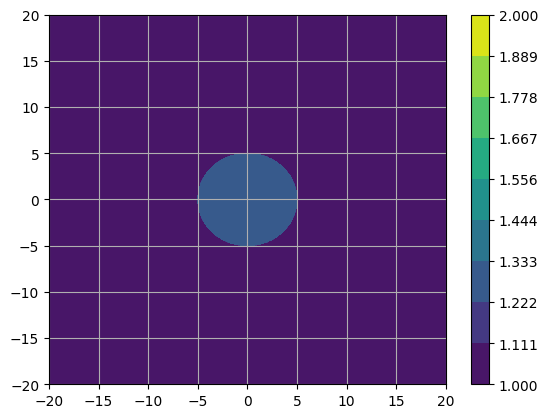

In [3]:
#Inicializamos el espacio y el espacio de indices
Espacio, EspacioIndices, X,Y = CrearEspacio(-20, 20,-20, 20, 1000, 1)
#Las siguientes tres son variables globales importantes, contienen la informacion del origen, radio e indice de refraccion de los circulos diaelectricos
# Sin estos el codigo no corre y 'O' tiene que ser una lista de listas
O = np.array([[0,0]])
R = np.array([5])
N = np.array([1.3])
DiaelectricoCircular(N[0], O[0], R[0])

plt.contourf(X, Y, EspacioIndices, levels= np.linspace(1,2,10))
plt.colorbar()
plt.grid(True)
plt.show()



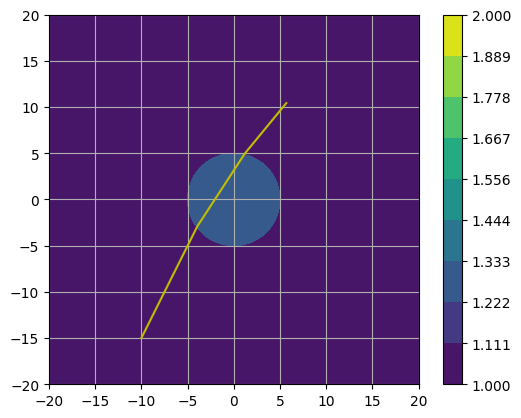

In [4]:
Vec1 = np.array([1.0, 2.0])          
Origen1 = np.array(([-10.0, -15.0]))
t = np.linspace(0, 30, 400)     

x3, y3 = Transmision(Vec1, t, Origen1)
# Dibujar
plt.contourf(X, Y, EspacioIndices, levels= np.linspace(1,2,10))
plt.plot(x3 , y3, color = 'y')
plt.axis('scaled')
plt.colorbar()
plt.grid(True)
plt.show()

[0 0]


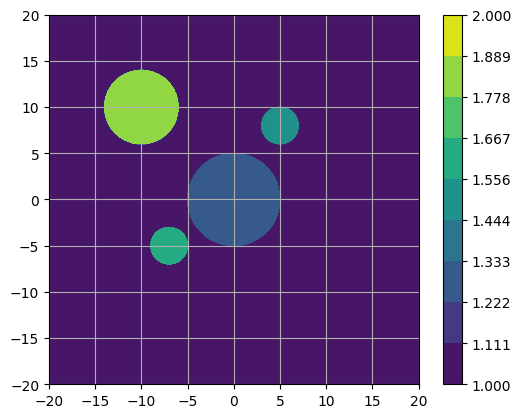

In [5]:
Espacio, EspacioIndices, X,Y = CrearEspacio(-20,20,-20,20, 1000,1)

O = np.array(([0,0],[5,8],[-7,-5],[-10,10])) 
R = np.array(([5,2,2,4]))
N = np.array([1.33, 1.5, 1.6, 1.8])
print(O[0])
DiaelectricoCircular(N[0], O[0], R[0])
DiaelectricoCircular(N[1], O[1], R[1])
DiaelectricoCircular(N[2], O[2], R[2])
DiaelectricoCircular(N[3], O[3], R[3])
# Dibujar
plt.contourf(X, Y, EspacioIndices, levels= np.linspace(1,2,10))
plt.axis('scaled')
plt.colorbar()
plt.grid(True)
plt.show()

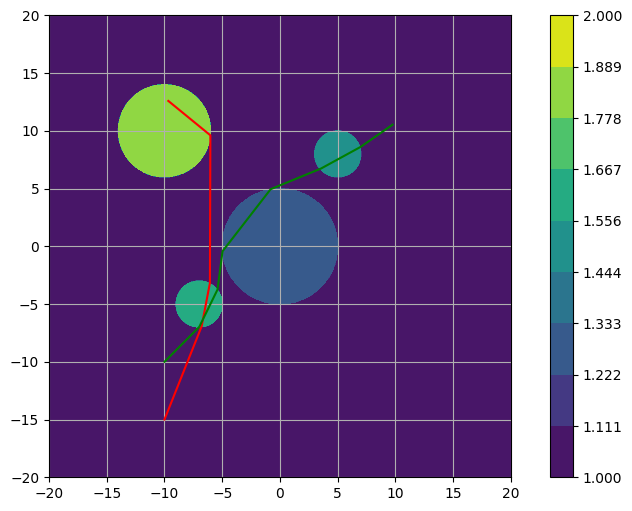

In [6]:
Vec1 = np.array([1.0, 2.5])           
Origen1 = np.array([-10.0, -15.0])
t = np.linspace(0, 30, 4000)                     

Vec2 = np.array([1.0, 1.0])           
Origen2 = np.array([-10.0, -10.0])
t = np.linspace(0, 30, 4000)  


x1, y1 = Transmision(Vec1, t, Origen1)
x2, y2 = Transmision(Vec2, t, Origen2)


plt.figure(figsize=(10,6))
plt.contourf(X, Y, EspacioIndices, levels= np.linspace(1,2,10))
plt.plot(x1, y1, color='r')
plt.plot(x2, y2, color = 'g')
plt.axis('scaled')
plt.colorbar()
plt.grid(True)
plt.show()

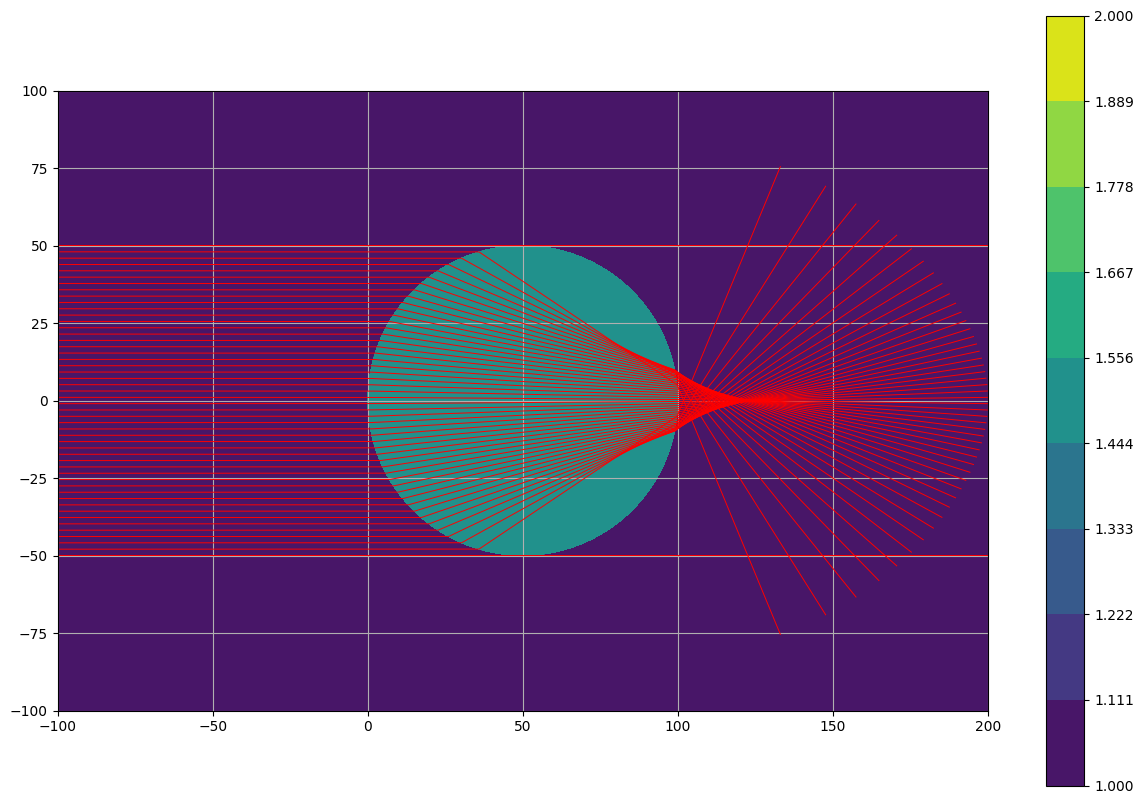

In [7]:
Espacio, EspacioIndices, X,Y = CrearEspacio(-100,200,-100,100, 10000,1)

# Globales que usa IndiceExacto y Transmision (deben reflejar el nuevo círculo)
O = np.array([[50, 0]])
R = np.array([50])
N = np.array([1.5])

DiaelectricoCircular(N[0], O[0], R[0])

# t más largo: con t hasta 50 los rayos solo avanzan 50 unidades y no llegan al círculo
t = np.linspace(0, 300, 5000)

Vec = np.array([1.0, 0.0])
Altura = np.linspace(-50, 50, 50)
OrigenVec = np.column_stack((np.full(Altura.size, -100.0), Altura))

# Dibujar

plt.figure(figsize=(15,10))
plt.contourf(X, Y, EspacioIndices, levels=np.linspace(1, 2, 10))

for Origen in OrigenVec:
    x, y = Transmision(Vec, t, Origen)
    plt.plot(x, y, color='r', linewidth=0.7)

plt.axis('scaled')
plt.xlim(-100, 200)
plt.ylim(-100, 100)
plt.colorbar()
plt.grid(True)
plt.show()